Using the code from myMFE site (https://pymfe.readthedocs.io/en/latest/using.html)

In [6]:
from sklearn.datasets import load_iris
from pymfe.mfe import MFE
import pandas as pd

# Load dataset
X, y = load_iris(return_X_y=True)

# Extract general meta-features
mfe_gen = MFE(groups=["general"])

# Prepare dataset
mfe_gen.fit(X, y)

# Extract meta-features
names_gen, values_gen = mfe_gen.extract()

# Display results
df_gen = pd.DataFrame({
    "Meta-Feature": names_gen,
    "Value": values_gen
})


mfe_stat = MFE(groups=["statistical"])
mfe_stat.fit(X, y)
names_stat, values_stat = mfe_stat.extract()
df_stat = pd.DataFrame({
    "Meta-Feature": names_stat,
    "Value": values_stat
})

# Display separate tables
print("GENERAL META-FEATURES")
display(df_gen)

print("STATISTICAL META-FEATURES")
display(df_stat)

GENERAL META-FEATURES


,Meta-Feature,Value
0,attr_to_inst,0.026667
1,cat_to_num,0.000000
2,freq_class.mean,0.333333
3,freq_class.sd,0.000000
4,inst_to_attr,37.500000
5,nr_attr,4.000000
6,nr_bin,0.000000
7,nr_cat,0.000000
8,nr_class,3.000000
9,nr_inst,150.000000


STATISTICAL META-FEATURES


,Meta-Feature,Value
0,can_cor.mean,0.728009
1,can_cor.sd,0.363187
2,cor.mean,0.594116
3,cor.sd,0.337544
4,cov.mean,0.596654
5,cov.sd,0.558267
6,eigenvalues.mean,1.143239
7,eigenvalues.sd,2.058771
8,g_mean.mean,3.223073
9,g_mean.sd,2.022943


Lets plot iris 

In [7]:
iris = load_iris()

df = pd.DataFrame(X, columns=iris.feature_names)
df["species"] = iris.target_names[y]

display(df.head(10))

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


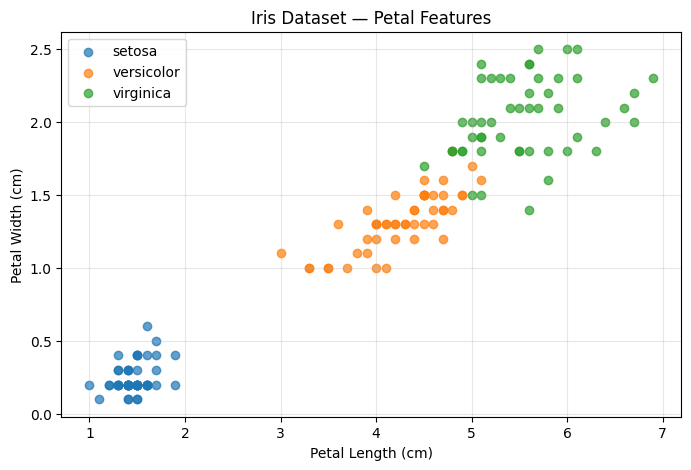

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for class_id, species in enumerate(iris.target_names):
    mask = y == class_id

    plt.scatter(
        X[mask, 2],
        X[mask, 3],
        label=species,
        alpha=0.7
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris Dataset — Petal Features")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

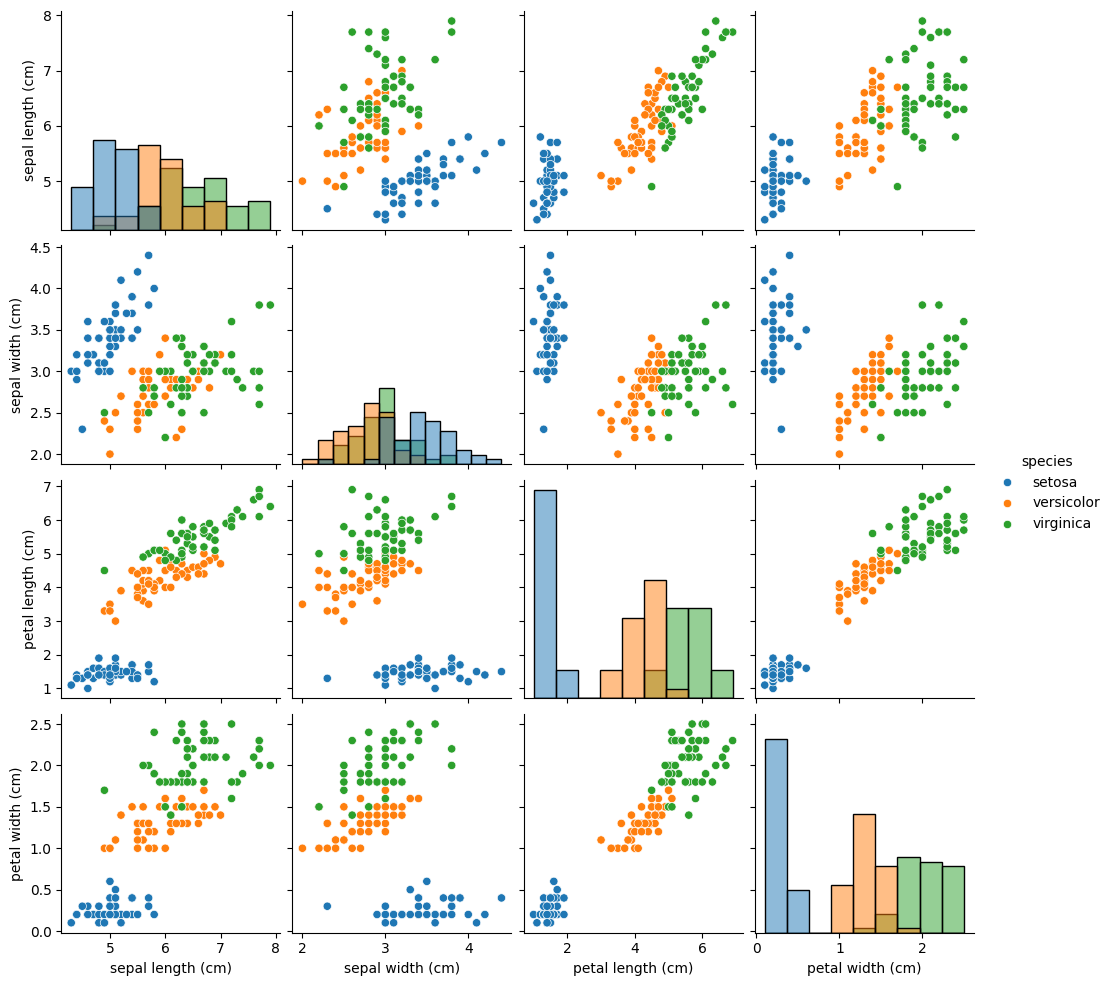

In [10]:
import seaborn as sns

sns.pairplot(df, hue="species", diag_kind="hist")
plt.show()

Correlations:

In [11]:
corr_matrix = pd.DataFrame(
    X, columns=iris.feature_names
).corr()

display(corr_matrix)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


For iris tabular data we will extract the next 10 meta features (the first six are gemeral and the last four are statistical):

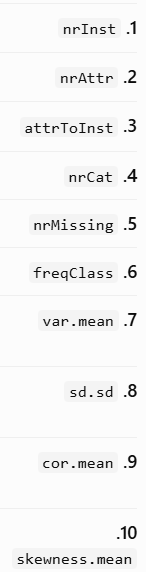

We will also calculate var.mean, sd.sd, cor.mean using pandas and numpy for understanding. 

In [ ]:
from sklearn.datasets import load_iris
from pymfe.mfe import MFE
import pandas as pd

# Load dataset
X, y = load_iris(return_X_y=True)

# Extract general meta-features
mfe_gen = MFE(groups=["general"])